# 05 — Attribution

In [1]:
import json
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import spearmanr, weightedtau
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

BRANCHES = ["original", "seasonal", "trend"]
MODEL_NAMES = ["XGBoost", "RandomForest", "Ridge"]
SEEDS = range(5)
CV = TimeSeriesSplit(n_splits=5)

BASE = {"XGBoost": XGBRegressor(n_jobs=1),
        "RandomForest": RandomForestRegressor(n_jobs=-1),
        "Ridge": make_pipeline(StandardScaler(), Ridge())}
params = json.load(open("../results/04_best_params.json"))


def make_model(b, name, seed):
    est = clone(BASE[name]).set_params(**params[f"{b}|{name}"])
    if name != "Ridge":
        est.set_params(random_state=seed)
    return est


def family(f):
    if f == "noise_probe":
        return "noise probe"
    if f.startswith("LST"):
        return "LST"
    if f.startswith("SPEI"):
        return "drought"
    if f.startswith("month"):
        return "calendar"
    return "own history"


short = lambda f: f.replace("NDVI_", "").replace("NDVI", "")

train, test = {}, {}
for b in BRANCHES:
    df = pd.read_csv(f"../data/processed/features_{b}.csv", index_col="date", parse_dates=True)
    X, y, tr = df.drop(columns=["target", "split"]), df["target"], df["split"] == "train"
    train[b], test[b] = (X[tr], y[tr]), (X[~tr], y[~tr])
    print(f"{b:9s} train {train[b][0].shape}  test {test[b][0].shape}")

original  train (238, 6)  test (36, 6)
seasonal  train (238, 7)  test (36, 7)
trend     train (252, 5)  test (36, 5)


## Permutation importance

In [2]:
def oof_permutation(b, name, seed):
    X, y = train[b]
    folds = []
    for fit_idx, val_idx in CV.split(X):
        model = make_model(b, name, seed).fit(X.iloc[fit_idx], y.iloc[fit_idx])
        r = permutation_importance(model, X.iloc[val_idx], y.iloc[val_idx],
                                   n_repeats=10, random_state=seed,
                                   scoring="neg_mean_squared_error")
        folds.append(r.importances_mean)
    return pd.Series(np.mean(folds, axis=0), index=X.columns)


perm = pd.concat({(b, name, seed): oof_permutation(b, name, seed)
                  for b in BRANCHES for name in MODEL_NAMES for seed in SEEDS},
                 names=["branch", "model", "seed", "feature"]).rename("importance")
perm_mean = perm.groupby(["branch", "model", "feature"]).mean()

for b in BRANCHES:
    t = perm_mean[b].unstack("model")[MODEL_NAMES]
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    print(f"\n{b}  (increase in MSE, x1e4)")
    print((t * 1e4).round(2).to_string())


original  (increase in MSE, x1e4)
model        XGBoost  RandomForest  Ridge
feature                                  
LST_lag1        8.83         12.04   1.69
NDVI_lag1       2.88          2.99   2.04
NDVI_lag24      0.48          0.65   2.36
NDVI_lag12     -0.13          0.32   3.03
SPEI_1_lag7     0.11          0.09   0.11
noise_probe     0.07          0.01  -0.05

seasonal  (increase in MSE, x1e4)
model           XGBoost  RandomForest  Ridge
feature                                     
LST_S_lag1         7.49          4.45   0.74
NDVI_S_lag24       0.58          1.15   3.00
NDVI_S_lag12       0.14          1.07   2.81
NDVI_S_lag1        0.97          0.66   0.81
month_sin          0.90          1.06   0.33
SPEI_24_S_lag6     0.01         -0.01   0.24
noise_probe        0.02          0.03  -0.03

trend  (increase in MSE, x1e4)
model          XGBoost  RandomForest  Ridge
feature                                    
NDVI_T_lag1       0.87          1.05   2.23
LST_T_lag1        0.03   

## Drop-column importance

In [3]:
def oof_mse(b, name, cols, seed):
    X, y = train[b]
    X = X[cols]
    errs = [np.mean((y.iloc[v] - make_model(b, name, seed).fit(X.iloc[f], y.iloc[f])
                                 .predict(X.iloc[v])) ** 2)
            for f, v in CV.split(X)]
    return np.mean(errs)


drop = {}
for b in BRANCHES:
    cols = list(train[b][0].columns)
    for name in MODEL_NAMES:
        seeds = [0] if name == "Ridge" else SEEDS          # Ridge is deterministic
        full = np.mean([oof_mse(b, name, cols, s) for s in seeds])
        for f in cols:
            reduced = np.mean([oof_mse(b, name, [c for c in cols if c != f], s) for s in seeds])
            drop[(b, name, f)] = reduced / full - 1

drop = pd.Series(drop, name="drop").rename_axis(["branch", "model", "feature"])

for b in BRANCHES:
    t = drop[b].unstack("model")[MODEL_NAMES]
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    print(f"\n{b}  (% increase in out-of-fold MSE when the feature is removed)")
    print((100 * t).round(1).to_string())


original  (% increase in out-of-fold MSE when the feature is removed)
model        XGBoost  RandomForest  Ridge
feature                                  
NDVI_lag1       33.7          23.5   14.2
LST_lag1        29.2          33.2   -0.2
NDVI_lag24       5.4          -0.0    8.1
NDVI_lag12      -2.1           2.2    8.9
SPEI_1_lag7      1.5          -0.4    0.9
noise_probe      1.4           0.3   -0.8

seasonal  (% increase in out-of-fold MSE when the feature is removed)
model           XGBoost  RandomForest  Ridge
feature                                     
LST_S_lag1         18.2          14.9   -1.3
NDVI_S_lag1         4.9           6.2    4.5
NDVI_S_lag24       -1.5           2.2   13.1
month_sin           1.3           4.6   -0.8
NDVI_S_lag12       -5.6          -1.0    9.8
SPEI_24_S_lag6     -0.0           0.2    2.1
noise_probe         0.0           0.6   -0.6

trend  (% increase in out-of-fold MSE when the feature is removed)
model          XGBoost  RandomForest   Ridge
feat

## SHAP

In [4]:
background = {b: train[b][0].sample(100, random_state=0) for b in BRANCHES}


def shap_values(b, name, seed=0):
    X, y = train[b]
    model = make_model(b, name, seed).fit(X, y)
    masker = shap.maskers.Independent(background[b], max_samples=len(background[b]))
    explainer = shap.PermutationExplainer(model.predict, masker, seed=0)
    return explainer(X, silent=True).values, model


shap_raw, shap_mean, checks = {}, {}, []
for b in BRANCHES:
    X = train[b][0]
    for name in MODEL_NAMES:
        sv, model = shap_values(b, name)
        shap_raw[(b, name)] = sv
        shap_mean[(b, name)] = pd.Series(np.abs(sv).mean(axis=0), index=X.columns)
        if name == "Ridge":
            scaler, ridge = model.named_steps["standardscaler"], model.named_steps["ridge"]
            exact = (scaler.transform(X) - scaler.transform(background[b]).mean(axis=0)) * ridge.coef_
            checks.append(dict(branch=b, max_abs_diff=np.abs(exact - sv).max(),
                               rho_coef_shap=spearmanr(np.abs(ridge.coef_),
                                                       np.abs(sv).mean(axis=0)).statistic))

shap_mean = pd.concat(shap_mean, names=["branch", "model", "feature"]).rename("shap")
print("Ridge checks"); print(pd.DataFrame(checks).round(4).to_string(index=False))

print(f"\n{'branch':9s} {'model':12s} Spearman(SHAP, permutation)")
for b in BRANCHES:
    for name in MODEL_NAMES:
        print(f"{b:9s} {name:12s} {spearmanr(shap_mean[b][name], perm_mean[b][name]).statistic:+.2f}")

Ridge checks
  branch  max_abs_diff  rho_coef_shap
original           0.0            1.0
seasonal           0.0            1.0
   trend           0.0            1.0

branch    model        Spearman(SHAP, permutation)
original  XGBoost      +0.31
original  RandomForest +0.09
original  Ridge        +0.37
seasonal  XGBoost      +0.43
seasonal  RandomForest +0.46
seasonal  Ridge        +0.43
trend     XGBoost      +0.30
trend     RandomForest +0.80
trend     Ridge        +0.50


### SHAP summary plots

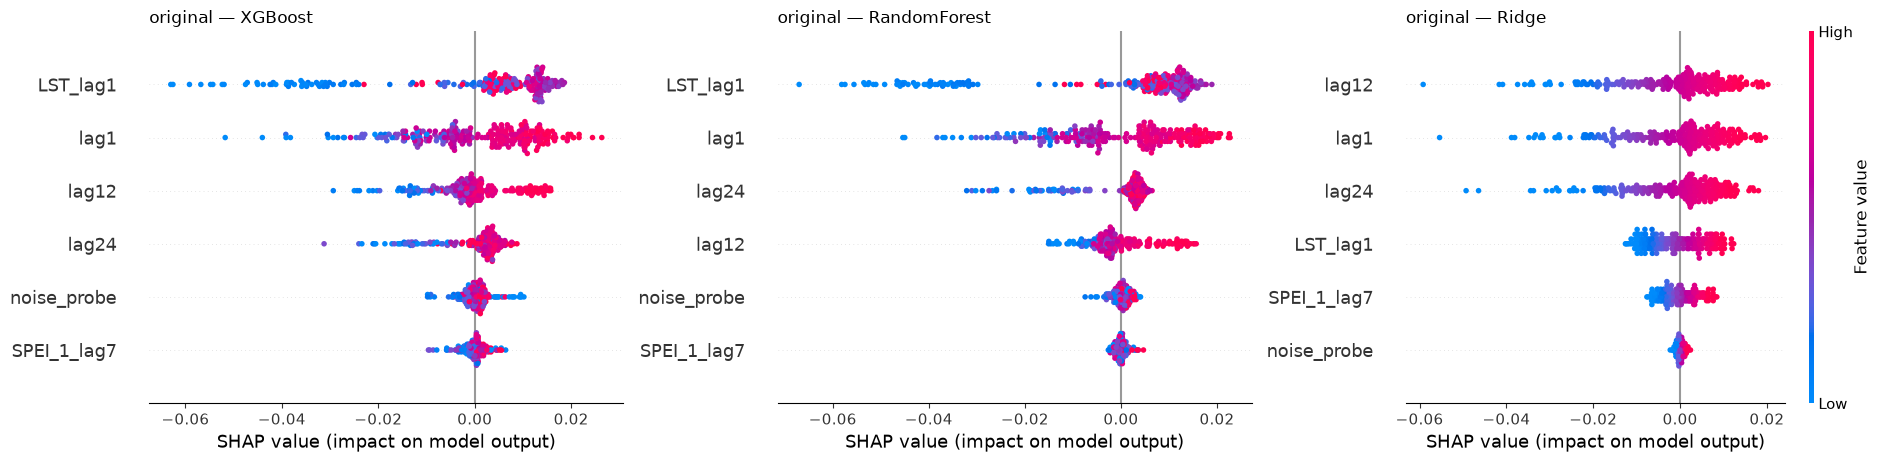

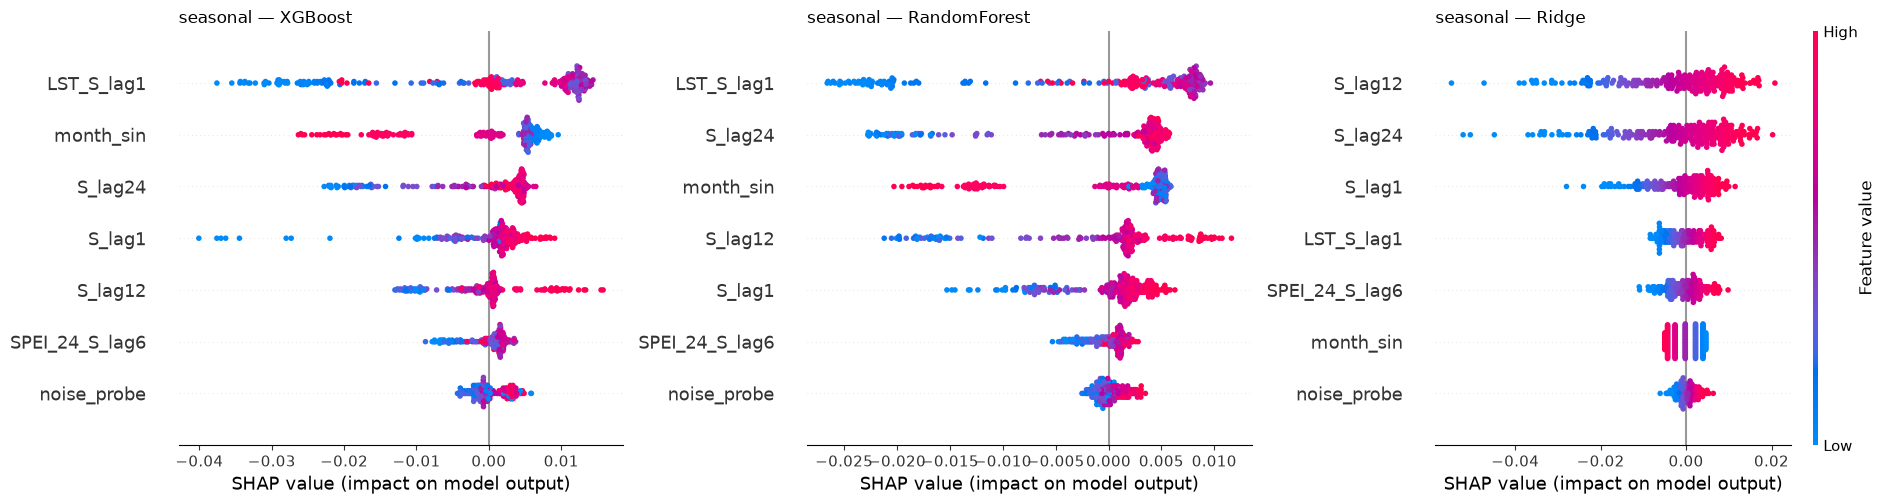

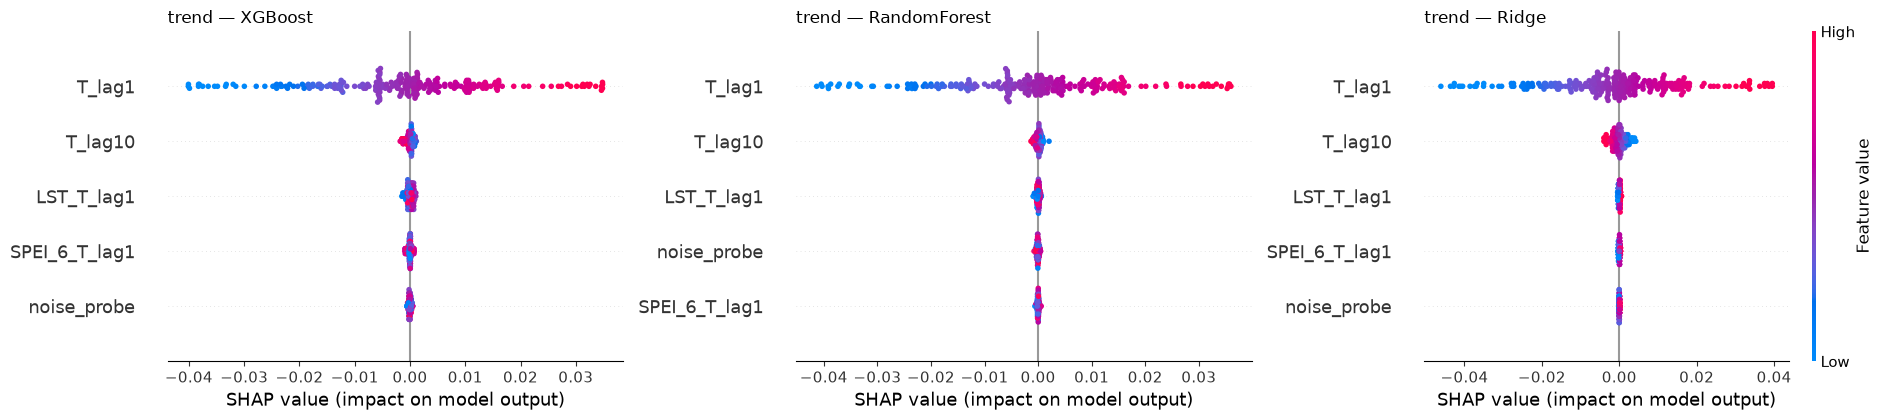

In [5]:
for b in BRANCHES:
    X = train[b][0]
    fig = plt.figure(figsize=(19, 0.42 * X.shape[1] + 2.2))
    for i, name in enumerate(MODEL_NAMES, start=1):
        ax = fig.add_subplot(1, 3, i)
        expl = shap.Explanation(shap_raw[(b, name)], data=X.to_numpy(),
                                feature_names=[short(f) for f in X.columns])
        shap.plots.beeswarm(expl, max_display=X.shape[1], show=False, ax=ax,
                            plot_size=None, color_bar=(i == 3))
        ax.set_title(f"{b} — {name}", loc="left")
    fig.tight_layout()
    fig.savefig(f"../figures/05_shap_{b}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Agreement between models

In [6]:
def shares(s):
    s = s.clip(lower=0)
    return s / s.sum()


def wtau(a, b):
    return weightedtau(a.to_numpy(), b.to_numpy()).statistic


def alloc(a, b):
    return 0.5 * np.abs(shares(a) - shares(b)).sum()


runs = {(b, m): [perm[b][m][s] for s in SEEDS] for b in BRANCHES for m in MODEL_NAMES}

rows, within = [], {}
for b in BRANCHES:
    for m in MODEL_NAMES:
        pairs = list(combinations(runs[(b, m)], 2))
        t, a = [wtau(x, y) for x, y in pairs], [alloc(x, y) for x, y in pairs]
        within[(b, m)] = (min(t), max(a))
        rows.append(dict(branch=b, pair=f"{m} vs itself", tau=np.median(t), tau_lo=min(t),
                         tau_hi=max(t), dist=np.median(a), dist_lo=min(a), dist_hi=max(a)))
    for m1, m2 in combinations(MODEL_NAMES, 2):
        pairs = [(x, y) for x in runs[(b, m1)] for y in runs[(b, m2)]]
        t, a = [wtau(x, y) for x, y in pairs], [alloc(x, y) for x, y in pairs]
        separable = (max(t) < min(within[(b, m1)][0], within[(b, m2)][0])
                     and min(a) > max(within[(b, m1)][1], within[(b, m2)][1]))
        rows.append(dict(branch=b, pair=f"{m1} vs {m2}", tau=np.median(t), tau_lo=min(t),
                         tau_hi=max(t), dist=np.median(a), dist_lo=min(a), dist_hi=max(a),
                         separable=separable))

agreement = pd.DataFrame(rows)
print(agreement.round(2).to_string(index=False))

  branch                    pair   tau  tau_lo  tau_hi  dist  dist_lo  dist_hi separable
original       XGBoost vs itself  0.93    0.80    1.00  0.03     0.02     0.06       NaN
original  RandomForest vs itself  1.00    1.00    1.00  0.02     0.01     0.03       NaN
original         Ridge vs itself  1.00    1.00    1.00  0.02     0.01     0.03       NaN
original XGBoost vs RandomForest  0.87    0.80    0.94  0.07     0.02     0.08     False
original        XGBoost vs Ridge -0.26   -0.32   -0.08  0.55     0.51     0.58      True
original   RandomForest vs Ridge -0.02   -0.02   -0.02  0.57     0.55     0.58      True
seasonal       XGBoost vs itself  0.87    0.72    0.96  0.04     0.02     0.07       NaN
seasonal  RandomForest vs itself  0.81    0.72    0.93  0.07     0.03     0.09       NaN
seasonal         Ridge vs itself  1.00    1.00    1.00  0.02     0.02     0.04       NaN
seasonal XGBoost vs RandomForest  0.61    0.47    0.87  0.23     0.19     0.29     False
seasonal        XGBoo

In [7]:
def top_k(s, k=3):
    return set(s.sort_values(ascending=False).index[:k])


print("top-3 features by permutation importance\n")
for b in BRANCHES:
    print(b)
    for name in MODEL_NAMES:
        print(f"  {name:12s} {sorted(short(f) for f in top_k(perm_mean[b][name]))}")
    for m1, m2 in combinations(MODEL_NAMES, 2):
        n = len(top_k(perm_mean[b][m1]) & top_k(perm_mean[b][m2]))
        print(f"    {m1} & {m2}: {n}/3 shared")

top-3 features by permutation importance

original
  XGBoost      ['LST_lag1', 'lag1', 'lag24']
  RandomForest ['LST_lag1', 'lag1', 'lag24']
  Ridge        ['lag1', 'lag12', 'lag24']
    XGBoost & RandomForest: 3/3 shared
    XGBoost & Ridge: 2/3 shared
    RandomForest & Ridge: 2/3 shared
seasonal
  XGBoost      ['LST_S_lag1', 'S_lag1', 'month_sin']
  RandomForest ['LST_S_lag1', 'S_lag12', 'S_lag24']
  Ridge        ['S_lag1', 'S_lag12', 'S_lag24']
    XGBoost & RandomForest: 1/3 shared
    XGBoost & Ridge: 1/3 shared
    RandomForest & Ridge: 2/3 shared
trend
  XGBoost      ['LST_T_lag1', 'T_lag1', 'T_lag10']
  RandomForest ['LST_T_lag1', 'T_lag1', 'noise_probe']
  Ridge        ['LST_T_lag1', 'T_lag1', 'T_lag10']
    XGBoost & RandomForest: 2/3 shared
    XGBoost & Ridge: 3/3 shared
    RandomForest & Ridge: 2/3 shared


## Probes

In [8]:
rows = []
for b in BRANCHES:
    for name in MODEL_NAMES:
        s = perm_mean[b][name].sort_values(ascending=False)
        lst = [f for f in s.index if f.startswith("LST")][0]
        rows.append(dict(branch=b, model=name, n_features=len(s),
                         noise_rank=s.index.get_loc("noise_probe") + 1,
                         lst_rank=s.index.get_loc(lst) + 1,
                         lst_share=shares(s)[lst],
                         below_noise=", ".join(short(f) for f in
                                               s.index[s.index.get_loc("noise_probe") + 1:])))
probes = pd.DataFrame(rows)
print(probes.assign(lst_share=probes.lst_share.round(3)).to_string(index=False))

  branch        model  n_features  noise_rank  lst_rank  lst_share            below_noise
original      XGBoost           6           5         1      0.714                  lag12
original RandomForest           6           6         1      0.748                       
original        Ridge           6           6         4      0.183                       
seasonal      XGBoost           7           6         1      0.741         SPEI_24_S_lag6
seasonal RandomForest           7           6         1      0.528         SPEI_24_S_lag6
seasonal        Ridge           7           7         4      0.093                       
   trend      XGBoost           5           4         3      0.031          SPEI_6_T_lag1
   trend RandomForest           5           3         2      0.026 SPEI_6_T_lag1, T_lag10
   trend        Ridge           5           5         3      0.004                       


## Family importance

In [9]:
def family_permutation(model, X, y, rng, n_repeats=10):
    fams = pd.Series({c: family(c) for c in X.columns})
    base = np.mean((y - model.predict(X)) ** 2)
    out = {}
    for fam, cols in fams.groupby(fams).groups.items():
        cols, inc = list(cols), []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            inc.append(np.mean((y - model.predict(Xp)) ** 2) - base)
        out[fam] = np.mean(inc)
    return pd.Series(out)


def oof_family(b, name, seed):
    X, y = train[b]
    rng = np.random.default_rng(seed)
    folds = [family_permutation(make_model(b, name, seed).fit(X.iloc[f], y.iloc[f]),
                                X.iloc[v], y.iloc[v], rng)
             for f, v in CV.split(X)]
    return pd.concat(folds, axis=1).mean(axis=1)


fam = pd.concat({(b, name, seed): oof_family(b, name, seed)
                 for b in BRANCHES for name in MODEL_NAMES for seed in SEEDS},
                names=["branch", "model", "seed", "family"])
fam_mean = fam.groupby(["branch", "model", "family"]).mean()
fam_share = fam_mean.clip(lower=0).groupby(["branch", "model"]).transform(lambda s: s / s.sum())
print(fam_share.unstack("model")[MODEL_NAMES].round(3).to_string())

model                 XGBoost  RandomForest  Ridge
branch   family                                   
original LST            0.492         0.615  0.093
         drought        0.007         0.007  0.006
         noise probe    0.005         0.002  0.000
         own history    0.496         0.377  0.900
seasonal LST            0.567         0.352  0.045
         calendar       0.064         0.083  0.017
         drought        0.000         0.000  0.015
         noise probe    0.001         0.002  0.000
         own history    0.368         0.563  0.924
trend    LST            0.026         0.025  0.004
         drought        0.000         0.000  0.001
         noise probe    0.001         0.000  0.000
         own history    0.973         0.974  0.996


## Why the trees need LST

In [10]:
VARIANTS = ["as used", "no LST", "climatology only", "anomaly only"]


def lst_cv_mse(b, name, seed, variant):
    X, y = train[b]
    c = [f for f in X.columns if f.startswith("LST")][0]
    month = pd.Series((X.index - pd.DateOffset(months=1)).month, index=X.index)
    errs = []
    for f, v in CV.split(X):
        Xf, Xv = X.iloc[f].copy(), X.iloc[v].copy()
        clim = Xf[c].groupby(month.iloc[f]).mean()
        cf, cv_ = month.iloc[f].map(clim).to_numpy(), month.iloc[v].map(clim).to_numpy()
        if variant == "no LST":
            Xf, Xv = Xf.drop(columns=c), Xv.drop(columns=c)
        elif variant == "climatology only":
            Xf[c], Xv[c] = cf, cv_
        elif variant == "anomaly only":
            Xf[c], Xv[c] = Xf[c] - cf, Xv[c] - cv_
        model = make_model(b, name, seed).fit(Xf, y.iloc[f])
        errs.append(np.mean((y.iloc[v] - model.predict(Xv)) ** 2))
    return np.mean(errs)


rows = []
for b in ["original", "seasonal"]:
    for name in MODEL_NAMES:
        seeds = [0] if name == "Ridge" else SEEDS
        mse = {v: np.mean([lst_cv_mse(b, name, s, v) for s in seeds]) for v in VARIANTS}
        rows.append(dict(branch=b, model=name,
                         **{v: 100 * (mse[v] / mse["as used"] - 1) for v in VARIANTS[1:]}))

mechanism = pd.DataFrame(rows)
print("% change in out-of-fold MSE relative to LST as used")
print(mechanism.round(1).to_string(index=False))

% change in out-of-fold MSE relative to LST as used
  branch        model  no LST  climatology only  anomaly only
original      XGBoost    29.2              10.8          25.3
original RandomForest    33.2               4.3          35.5
original        Ridge    -0.2              -0.0           2.5
seasonal      XGBoost    18.2               3.9          24.6
seasonal RandomForest    14.9               1.4          17.1
seasonal        Ridge    -1.3              -0.3           2.1


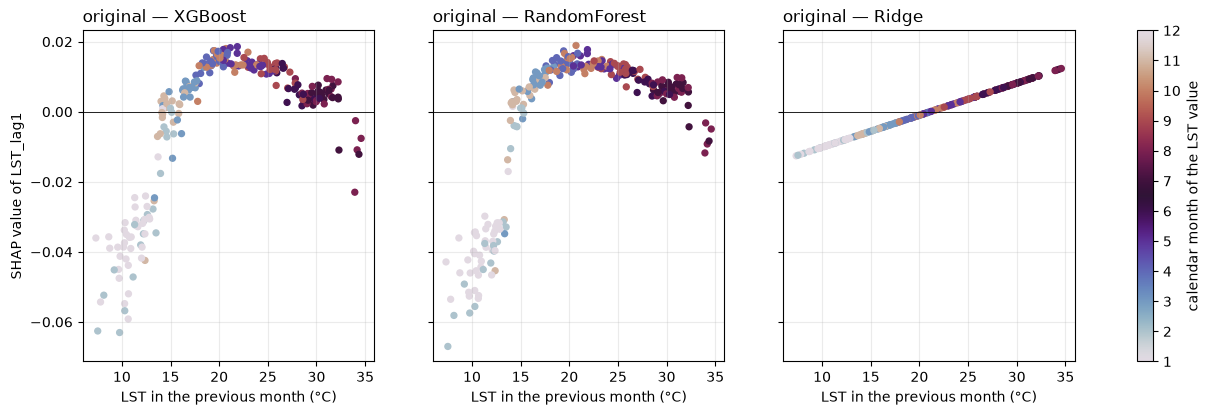

In [11]:
X = train["original"][0]
prev_month = (X.index - pd.DateOffset(months=1)).month
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    j = list(X.columns).index("LST_lag1")
    sc = ax.scatter(X["LST_lag1"], shap_raw[("original", name)][:, j], c=prev_month,
                    cmap="twilight", s=18, vmin=1, vmax=12)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlabel("LST in the previous month (°C)")
    ax.set_title(f"original — {name}", loc="left")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("SHAP value of LST_lag1")
fig.colorbar(sc, ax=axes, label="calendar month of the LST value", ticks=range(1, 13))
fig.savefig("../figures/05_lst_mechanism.png", dpi=150, bbox_inches="tight")
plt.show()

## Explanations during the 2022–2024 drought

In [12]:
rows = []
for b in BRANCHES:
    (Xtr, ytr), (Xte, yte) = train[b], test[b]
    for name in MODEL_NAMES:
        imp, famx = [], []
        for s in SEEDS:
            model = make_model(b, name, s).fit(Xtr, ytr)
            r = permutation_importance(model, Xte, yte, n_repeats=10, random_state=s,
                                       scoring="neg_mean_squared_error")
            imp.append(pd.Series(r.importances_mean, index=Xte.columns))
            famx.append(family_permutation(model, Xte, yte, np.random.default_rng(s)))
        imp, famx = pd.concat(imp, axis=1).mean(axis=1), pd.concat(famx, axis=1).mean(axis=1)
        ft, fd = shares(fam_mean[b][name]), shares(famx)
        rows.append(dict(branch=b, model=name, tau_train_vs_test=wtau(perm_mean[b][name], imp),
                         drought_train=ft.get("drought", 0), drought_test=fd.get("drought", 0),
                         LST_train=ft["LST"], LST_test=fd["LST"],
                         own_train=ft["own history"], own_test=fd["own history"]))

drought_shift = pd.DataFrame(rows)
print(drought_shift.round(3).to_string(index=False))

  branch        model  tau_train_vs_test  drought_train  drought_test  LST_train  LST_test  own_train  own_test
original      XGBoost             -0.015          0.007         0.000      0.492     0.590      0.496     0.410
original RandomForest             -0.091          0.007         0.000      0.615     0.745      0.377     0.255
original        Ridge              0.320          0.006         0.016      0.093     0.086      0.900     0.898
seasonal      XGBoost             -0.222          0.000         0.004      0.567     0.417      0.368     0.513
seasonal RandomForest             -0.102          0.000         0.009      0.352     0.290      0.563     0.655
seasonal        Ridge              0.233          0.015         0.012      0.045     0.030      0.924     0.953
   trend      XGBoost              0.015          0.000         0.002      0.026     0.000      0.973     0.997
   trend RandomForest              0.672          0.000         0.000      0.025     0.000      0.974   

## Figure: share of permutation importance

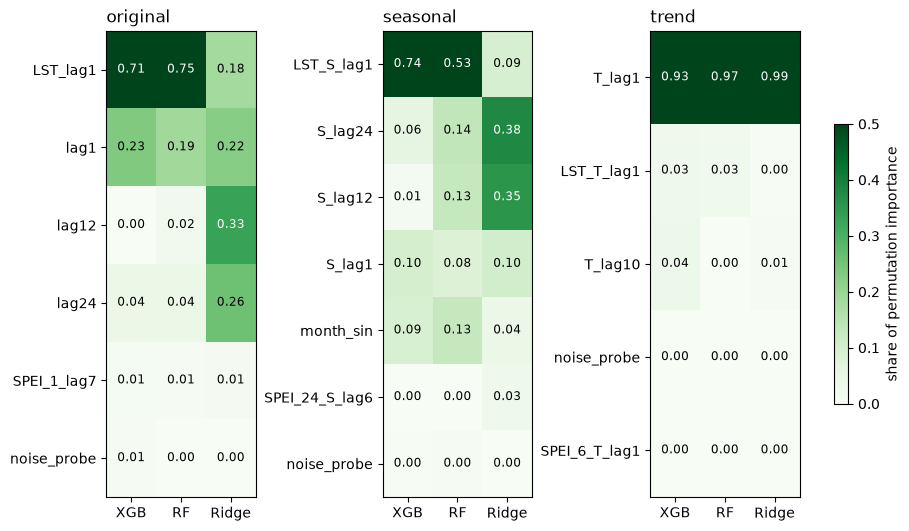

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(9, 5.2), layout="constrained")
for ax, b in zip(axes, BRANCHES):
    t = perm_mean[b].unstack("model")[MODEL_NAMES].apply(shares)
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    im = ax.imshow(t, cmap="Greens", vmin=0, vmax=0.5, aspect="auto")
    for (i, j), v in np.ndenumerate(t.to_numpy()):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.3 else "black")
    ax.set_xticks(range(3), ["XGB", "RF", "Ridge"])
    ax.set_yticks(range(len(t)), [short(f) for f in t.index])
    ax.set_title(b, loc="left")
fig.colorbar(im, ax=axes, shrink=0.6, label="share of permutation importance")
fig.savefig("../figures/05_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## Saving

In [14]:
perm.to_csv("../results/05_permutation_by_seed.csv")
pd.concat([perm_mean, drop, shap_mean], axis=1).to_csv("../results/05_importance.csv")
agreement.to_csv("../results/05_agreement.csv", index=False)
probes.to_csv("../results/05_probes.csv", index=False)
fam_share.rename("share").to_csv("../results/05_family_shares.csv")
mechanism.to_csv("../results/05_lst_mechanism.csv", index=False)
drought_shift.to_csv("../results/05_drought_shift.csv", index=False)
print("saved")

saved
